# ENME 485/691 Industrial AI, Homework 02
## Health assessment of a rotor shaft with logistic regression

**Objective.** Implement the analytical tools (signal processing, feature extraction, feature selection, logistic regression) and assess the health of the shaft in a rotor-bearing testbed from accelerometer data.

**Testbed summary**

| Item | Value |
|---|---|
| Nominal rotating speed | 20 Hz (1X) |
| Sampling rate | 2560 Hz |
| Record length | 38 400 samples = 15 s per observation |
| Training, healthy | 20 records (no screws) |
| Training, faulty | 20 records (unbalance level 2, two screws) |
| Testing, unknown | 30 records |

**Approaches implemented in this notebook**

1. Frequency-domain feature extraction: amplitude of the 1X harmonic (suggested feature) plus 2X and 3X harmonics.
2. Time-domain features: RMS, peak, crest factor, kurtosis, skewness, and a low-frequency band RMS.
2b. Noise filtering study: zero-phase Butterworth low-pass / band-pass filters, and their effect on spectral and time-domain features.
3. Feature selection with the Fisher discriminant ratio and Welch's t-test.
4. Logistic regression implemented **from scratch** (Newton-Raphson / IRLS) and validated against scikit-learn.
5. Four logistic regression models: (A) 1X amplitude only, (B) harmonic features 1X, 2X, 3X, (C) all features with standardization and L2 regularization, (D) time-domain features of the band-pass filtered signal.
6. Cross-validated model evaluation (leave-one-out and stratified 5-fold).
7. Health assessment of the 30 test records: probability of fault, hard label, and a continuous health index.

**Solution flow**

```
raw .txt records ──> parse header / load acceleration ──> Hann-window FFT
      │                                                        │
      │                              1X, 2X, 3X amplitude + band RMS (frequency domain)
      ├──> RMS, peak, crest, kurtosis, skewness (time domain) ─┤
      └──> band-pass 15-30 Hz ──> RMS, crest of filtered signal ─┤
                                                               ▼
                       feature ranking (Fisher ratio, t-test) ──> standardize ──> logistic regression
                                                                                        │
                    cross-validation (LOO, 5-fold) <──── models A / B / C / D ──> score 30 test records
                                                                                        │
                                                          P(faulty), label, health index, majority vote
```

## 1. Setup
Imports, physical constants of the testbed, plotting style, and a fixed color assignment (blue = healthy, orange = faulty, gray = unknown test record).

In [1]:
# Imports, constants, and a consistent plotting style used throughout the notebook.
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal, stats
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, LeaveOneOut, StratifiedKFold

FS = 2560.0        # sampling rate [Hz]
F_ROT = 20.0       # nominal shaft speed [Hz]  (1X)

# Locate the data folder whether the notebook is run from hw2/ or from the repo root.
DATA_DIR = next(p for p in (Path("../data/rotor-bearing"), Path("data/rotor-bearing")) if p.exists()).resolve()
OUT_DIR = Path("results"); OUT_DIR.mkdir(exist_ok=True)

# Fixed categorical colors: the same entity always gets the same color.
C_HEALTHY, C_FAULTY, C_TEST = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "lines.linewidth": 1.2, "font.size": 9.5, "legend.frameon": False,
})
pd.set_option("display.precision", 5)
print("Data folder:", DATA_DIR)

Data folder: C:\Users\yjun\code\coursework\enme691\data\rotor-bearing


## 2. Data loading
Each text file has a 5-line header (`Date`, `Time`, `Operator`, blank, `Acceleration`) followed by one acceleration value per line. The loader finds the `Acceleration` marker so it does not depend on the exact header length, and the file name gives the acquisition time (`HHMM`) and record index used to order the test records chronologically.

In [2]:
# Read one record: return the acceleration vector as a NumPy array.
def load_record(path: Path) -> np.ndarray:
    lines = path.read_text().splitlines()
    start = next(i for i, l in enumerate(lines) if l.strip().lower() == "acceleration") + 1
    return np.array([float(v) for v in lines[start:] if v.strip()])

# Parse "... Time HHMM-idx.txt" into (time string, record index) for sorting/labeling.
def parse_name(path: Path):
    m = re.search(r"Time (\d{4})-(\d+)", path.name)
    return m.group(1), int(m.group(2))

def load_folder(folder: Path, label):
    recs = []
    for p in sorted(folder.glob("*.txt")):
        t, idx = parse_name(p)
        recs.append({"file": p.name, "time": t, "idx": idx, "label": label, "x": load_record(p)})
    return recs

healthy = load_folder(DATA_DIR / "Training" / "Healthy", 0)   # label 0 = healthy
faulty  = load_folder(DATA_DIR / "Training" / "Faulty", 1)    # label 1 = faulty (unbalance level 2)
testing = sorted(load_folder(DATA_DIR / "Testing", None), key=lambda r: (r["time"], r["idx"]))

print(f"healthy: {len(healthy)} records, faulty: {len(faulty)} records, testing: {len(testing)} records")
print("samples per record:", {len(r['x']) for r in healthy + faulty + testing}, "->", len(healthy[0]['x']) / FS, "s each")

healthy: 20 records, faulty: 20 records, testing: 30 records
samples per record: {38400} -> 15.0 s each


## 3. Raw data description
Basic statistics of the raw acceleration per class, and a look at the time waveforms. Unbalance produces a sinusoidal force at the shaft frequency, so we expect a stronger low-frequency (1X) oscillation in the faulty records even if the overall vibration level looks similar.

In [3]:
# Per-class summary statistics of the raw acceleration signals.
def raw_stats(recs, name):
    x = np.concatenate([r["x"] for r in recs])
    return pd.Series({"records": len(recs), "samples/record": len(recs[0]["x"]), "mean": x.mean(),
                      "std": x.std(), "min": x.min(), "max": x.max()}, name=name)

pd.DataFrame([raw_stats(healthy, "healthy (train)"), raw_stats(faulty, "faulty (train)"), raw_stats(testing, "testing")])

,records,samples/record,mean,std,min,max
healthy (train),20.0,38400.0,0.00024,0.08058,-1.39355,0.83632
faulty (train),20.0,38400.0,0.00004,0.06364,-0.52041,0.50749
testing,30.0,38400.0,0.00032,0.07065,-0.74104,0.50327


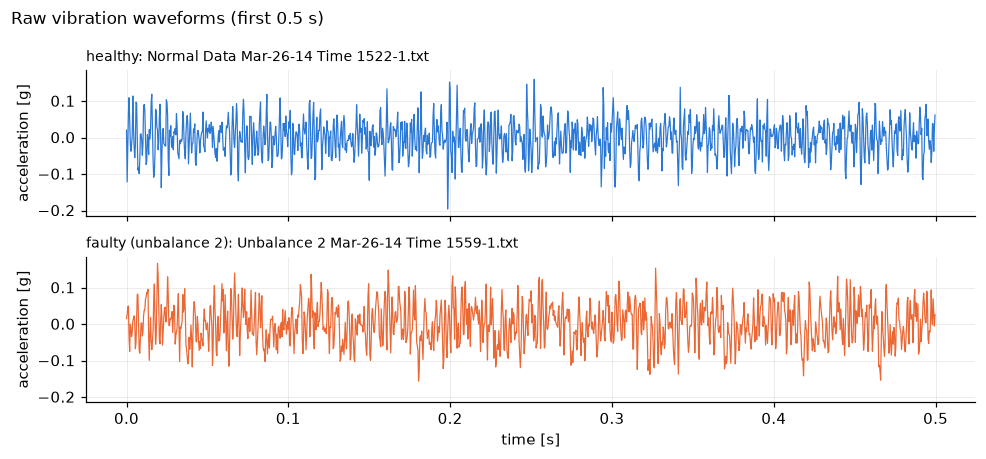

In [4]:
# Time waveforms: one healthy and one faulty training record, first 0.5 s (about 10 shaft revolutions).
t = np.arange(len(healthy[0]["x"])) / FS
n_show = int(0.5 * FS)
fig, axes = plt.subplots(2, 1, figsize=(9, 4.2), sharex=True, sharey=True)
for ax, rec, c, name in [(axes[0], healthy[0], C_HEALTHY, "healthy"), (axes[1], faulty[0], C_FAULTY, "faulty (unbalance 2)")]:
    ax.plot(t[:n_show], rec["x"][:n_show], color=c, lw=0.8)
    ax.set_title(f"{name}: {rec['file']}", loc="left", fontsize=9)
    ax.set_ylabel("acceleration [g]")
axes[1].set_xlabel("time [s]")
fig.suptitle("Raw vibration waveforms (first 0.5 s)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); plt.show()

## 4. Frequency-domain analysis
A Hann-windowed FFT gives the single-sided amplitude spectrum, scaled so that a pure sinusoid of amplitude *A* shows a peak of height *A*. With 38 400 samples the frequency resolution is 2560/38400 = 0.067 Hz. The spectra reveal that the actual shaft frequency is about 21 Hz (slightly above the nominal 20 Hz), so harmonic amplitudes are searched in a band around the nominal value rather than at exactly 20 Hz.

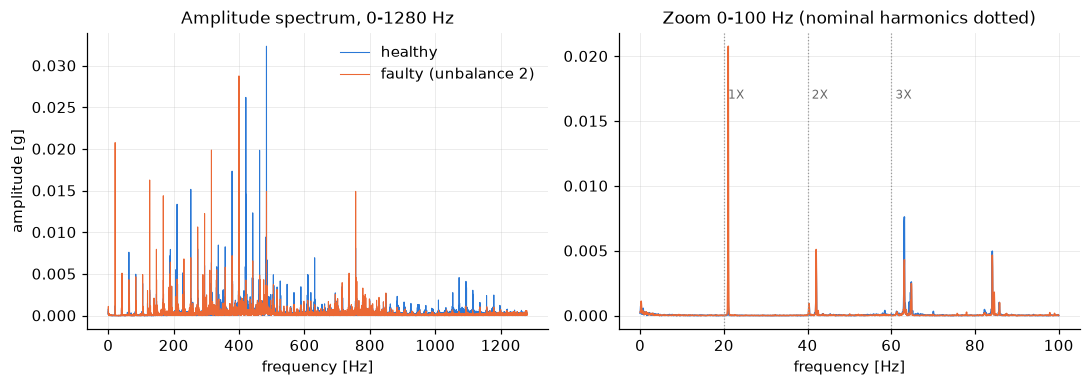

In [5]:
# Single-sided amplitude spectrum with a Hann window (amplitude-corrected by the window sum).
def amplitude_spectrum(x: np.ndarray):
    x = x - x.mean()
    w = np.hanning(len(x))
    X = np.fft.rfft(x * w)
    f = np.fft.rfftfreq(len(x), d=1 / FS)
    return f, 2.0 * np.abs(X) / w.sum()

# Compare spectra of one healthy and one faulty record: full band and a zoom on the low frequencies.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for rec, c, name in [(healthy[0], C_HEALTHY, "healthy"), (faulty[0], C_FAULTY, "faulty (unbalance 2)")]:
    f, A = amplitude_spectrum(rec["x"])
    axes[0].plot(f, A, color=c, lw=0.7, label=name)
    axes[1].plot(f[f <= 100], A[f <= 100], color=c, lw=1.0, label=name)
ymax = axes[1].get_ylim()[1]
for k in (1, 2, 3):
    axes[1].axvline(k * F_ROT, color="0.6", ls=":", lw=0.8)
    axes[1].text(k * F_ROT + 1.0, ymax * 0.80, f"{k}X", color="0.4", fontsize=8, va="top")
axes[0].set(title="Amplitude spectrum, 0-1280 Hz", xlabel="frequency [Hz]", ylabel="amplitude [g]")
axes[1].set(title="Zoom 0-100 Hz (nominal harmonics dotted)", xlabel="frequency [Hz]")
axes[0].legend(loc="upper right")
fig.tight_layout(); plt.show()

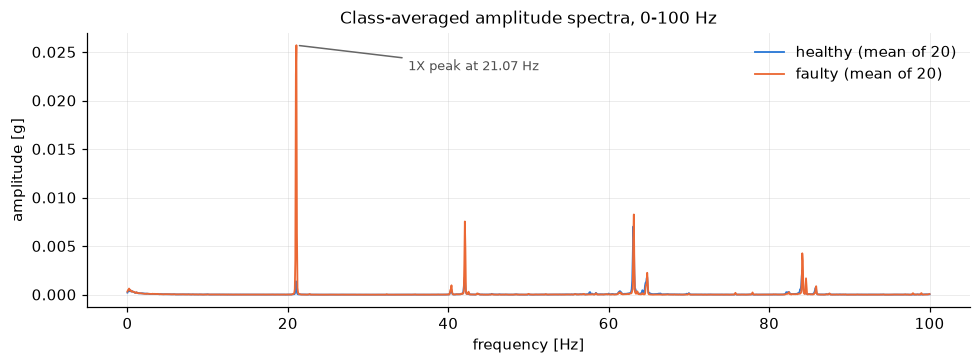

Measured shaft frequency (1X) from the faulty class mean spectrum: 21.067 Hz  (nominal 20 Hz)


In [6]:
# Class-averaged spectra (0-100 Hz): averaging over the 20 records of each class shows the systematic 1X difference.
def mean_spectrum(recs):
    specs = [amplitude_spectrum(r["x"])[1] for r in recs]
    return amplitude_spectrum(recs[0]["x"])[0], np.mean(specs, axis=0)

f, A_h = mean_spectrum(healthy)
_, A_f = mean_spectrum(faulty)
m = f <= 100
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(f[m], A_h[m], color=C_HEALTHY, label="healthy (mean of 20)")
ax.plot(f[m], A_f[m], color=C_FAULTY, label="faulty (mean of 20)")
f_peak = f[m][np.argmax(A_f[m] * (f[m] < 30))]
ax.annotate(f"1X peak at {f_peak:.2f} Hz", xy=(f_peak, A_f[m].max()), xytext=(35, A_f[m].max() * 0.9),
            arrowprops=dict(arrowstyle="-", color="0.4"), fontsize=8.5, color="0.3")
ax.set(xlabel="frequency [Hz]", ylabel="amplitude [g]", title="Class-averaged amplitude spectra, 0-100 Hz")
ax.legend(); fig.tight_layout(); plt.show()
print(f"Measured shaft frequency (1X) from the faulty class mean spectrum: {f_peak:.3f} Hz  (nominal {F_ROT:.0f} Hz)")

### 4.3 Effect of noise filtering
The raw waveform is dominated by high-frequency content (400-800 Hz) that has nothing to do with unbalance. Two zero-phase Butterworth filters (4th order, applied forward and backward with `sosfiltfilt` so no phase distortion; 1 s is trimmed at both ends to discard filter start-up transients) are compared against the raw signal:

* **low-pass 100 Hz**: keeps the first few shaft harmonics,
* **band-pass 15-30 Hz**: isolates the 1X component.

Two questions are answered: (1) does filtering improve the 1X amplitude estimated from the spectrum, and (2) does it make time-domain statistics usable as health features?

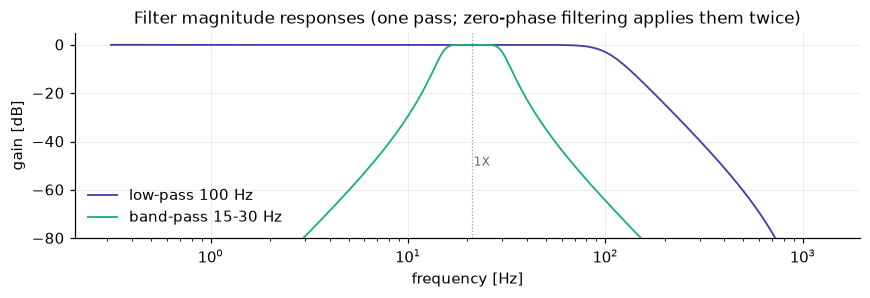

In [7]:
# Zero-phase Butterworth filters (second-order sections for numerical stability).
SOS_LP = signal.butter(4, 100.0, btype="low", fs=FS, output="sos")          # low-pass 100 Hz
SOS_BP = signal.butter(4, [15.0, 30.0], btype="band", fs=FS, output="sos")  # band-pass around 1X

TRIM = int(1.0 * FS)   # drop 1 s at each end: filtfilt start-up transients would otherwise inflate peak/crest of quiet signals
def lowpass(x):  return signal.sosfiltfilt(SOS_LP, x)[TRIM:-TRIM]
def bandpass(x): return signal.sosfiltfilt(SOS_BP, x)[TRIM:-TRIM]

# Filter frequency responses.
fig, ax = plt.subplots(figsize=(8, 2.8))
for sos, name, c in [(SOS_LP, "low-pass 100 Hz", "#4a3aa7"), (SOS_BP, "band-pass 15-30 Hz", "#1baf7a")]:
    w, h = signal.sosfreqz(sos, worN=4096, fs=FS)
    ax.semilogx(w[1:], 20 * np.log10(np.abs(h[1:]) + 1e-12), color=c, label=name)
ax.axvline(21.05, color="0.6", ls=":", lw=0.8); ax.text(21.5, -50, "1X", color="0.4", fontsize=8)
ax.set(ylim=(-80, 5), xlabel="frequency [Hz]", ylabel="gain [dB]", title="Filter magnitude responses (one pass; zero-phase filtering applies them twice)")
ax.legend(loc="lower left"); fig.tight_layout(); plt.show()

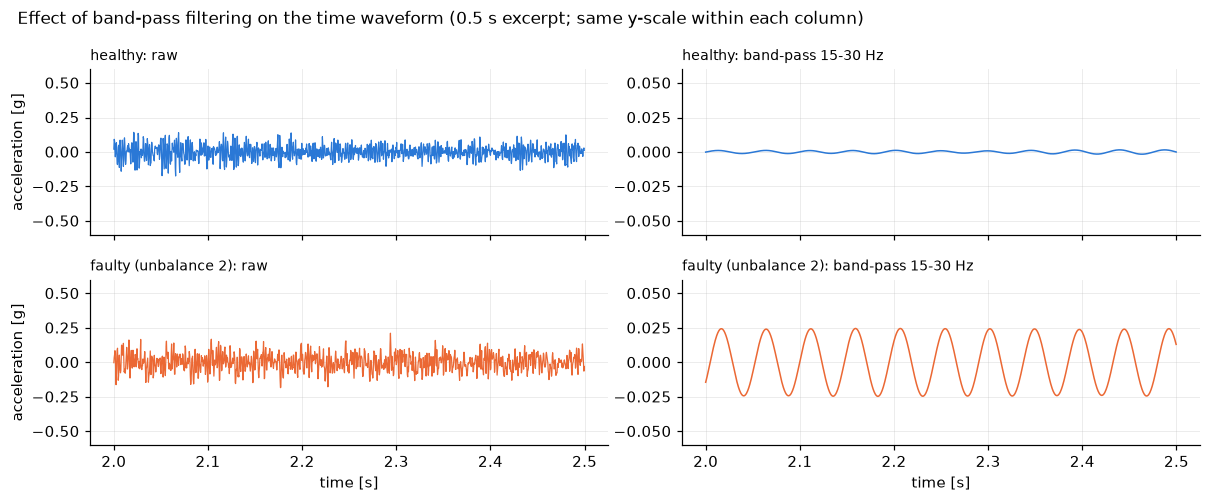

In [8]:
# Raw vs band-pass filtered waveforms: after filtering, the 21 Hz unbalance oscillation of the faulty shaft is obvious.
fig, axes = plt.subplots(2, 2, figsize=(11, 4.6), sharex=True)
for row, (rec, c, name) in enumerate([(healthy[0], C_HEALTHY, "healthy"), (faulty[0], C_FAULTY, "faulty (unbalance 2)")]):
    x = rec["x"]; xb = bandpass(x); i0 = int(2.0 * FS)          # excerpt from t = 2 s to 2.5 s
    axes[row, 0].plot(t[i0:i0 + n_show], x[i0:i0 + n_show], color=c, lw=0.8)
    axes[row, 1].plot(t[i0:i0 + n_show], xb[i0 - TRIM:i0 - TRIM + n_show], color=c, lw=1.0)
    axes[row, 0].set_title(f"{name}: raw", loc="left", fontsize=9); axes[row, 1].set_title(f"{name}: band-pass 15-30 Hz", loc="left", fontsize=9)
    axes[row, 0].set_ylabel("acceleration [g]")
for ax in axes[1]: ax.set_xlabel("time [s]")
for ax in axes[:, 0]: ax.set_ylim(-0.6, 0.6)
for ax in axes[:, 1]: ax.set_ylim(-0.06, 0.06)
fig.suptitle("Effect of band-pass filtering on the time waveform (0.5 s excerpt; same y-scale within each column)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); plt.show()

In [9]:
# Does filtering change the 1X amplitude read from the spectrum?  (raw and filtered compared on the same trimmed length)
def one_x(x):
    f, A = amplitude_spectrum(x); m = (f >= 17) & (f <= 23); return A[m].max()

def snr_1x_db(x):
    f, A = amplitude_spectrum(x); m = (f >= 17) & (f <= 23)
    noise = np.median(A[(f >= 10) & (f <= 35) & ~((f >= 20.5) & (f <= 21.6))])   # local noise floor next to the peak
    return 20 * np.log10(A[m].max() / noise)

chk = pd.DataFrame([{"A1X_raw": one_x(r["x"][TRIM:-TRIM]), "A1X_lowpass": one_x(lowpass(r["x"])), "A1X_bandpass": one_x(bandpass(r["x"])),
                     "SNR_raw_dB": snr_1x_db(r["x"][TRIM:-TRIM]), "SNR_lowpass_dB": snr_1x_db(lowpass(r["x"]))} for r in healthy + faulty])
print("max |A1X_raw - A1X_lowpass|  =", f"{(chk.A1X_raw - chk.A1X_lowpass).abs().max():.2e} g")
print("max |A1X_raw - A1X_bandpass| =", f"{(chk.A1X_raw - chk.A1X_bandpass).abs().max():.2e} g")
print("mean 1X SNR raw / low-pass  =", f"{chk.SNR_raw_dB.mean():.1f} dB / {chk.SNR_lowpass_dB.mean():.1f} dB")

max |A1X_raw - A1X_lowpass|  = 1.08e-07 g
max |A1X_raw - A1X_bandpass| = 7.59e-11 g
mean 1X SNR raw / low-pass  = 48.2 dB / 48.2 dB


**Finding.** Pre-filtering leaves the spectral 1X amplitude untouched (differences at the 1e-7 g level) and does not change its signal-to-noise ratio: a linear, zero-phase filter with a flat pass-band at 21 Hz multiplies that bin by 1, and the 15-s FFT already acts as a 0.067 Hz-wide filter bank, so the broadband noise never reached the 1X bin in the first place. Filtering is therefore unnecessary for the frequency-domain features. Whether it helps the *time-domain* features is answered in sections 5 and 6, where every time-domain statistic is computed on both the raw and the band-pass filtered signal and the two versions are compared side by side.

## 5. Feature extraction
For every record we compute two families of features.

**Frequency-domain features** (from the Hann-windowed spectrum of the raw signal; section 4.3 showed that filtering does not change them):

* **A1X, A2X, A3X**: amplitude of the 1X, 2X, 3X harmonics. The 1X peak is searched in ±15 % around the nominal 20 Hz, then 2X and 3X are searched in ±1 Hz around multiples of the *measured* 1X frequency. `f1X` (the measured shaft frequency) is stored for reference but not used as a feature.
* **rms_lf**: RMS of the 0-100 Hz band computed from the spectrum (Parseval).
* **ratio_1X**: A1X divided by the overall RMS, a normalized unbalance indicator.

**Time-domain features**, each computed **twice**: on the raw signal (suffix `_raw`) and on the 15-30 Hz band-pass filtered signal (suffix `_bp`), so that the effect of filtering can be compared feature by feature:

* **rms, peak, crest** (peak / RMS), **kurtosis, skewness**.

In [10]:
# Harmonic amplitude: maximum of the spectrum inside a band around the expected frequency.
def band_peak(f, A, f_center, half_width):
    m = (f >= f_center - half_width) & (f <= f_center + half_width)
    i = np.argmax(A[m])
    return A[m][i], f[m][i]

TD_STATS = ["rms", "peak", "crest", "kurtosis", "skewness"]

# Time-domain statistics of a signal, with a suffix telling which signal they came from.
def time_domain_features(x: np.ndarray, tag: str) -> dict:
    rms = np.sqrt(np.mean(x ** 2)); peak = np.max(np.abs(x))
    return {f"rms_{tag}": rms, f"peak_{tag}": peak, f"crest_{tag}": peak / rms,
            f"kurtosis_{tag}": stats.kurtosis(x), f"skewness_{tag}": stats.skew(x)}

# Full feature vector for one record.
def extract_features(x: np.ndarray) -> dict:
    f, A = amplitude_spectrum(x)
    a1, f1 = band_peak(f, A, F_ROT, 0.15 * F_ROT)          # 1X: search 17-23 Hz
    a2, _  = band_peak(f, A, 2 * f1, 1.0)                    # 2X around 2 * measured 1X
    a3, _  = band_peak(f, A, 3 * f1, 1.0)                    # 3X around 3 * measured 1X
    lf = (f > 0) & (f <= 100)
    d = {"A1X": a1, "A2X": a2, "A3X": a3, "f1X": f1,
         "rms_lf": np.sqrt(np.sum((A[lf] / np.sqrt(2)) ** 2)),   # band RMS from sinusoid amplitudes
         "ratio_1X": a1 / np.sqrt(np.mean(x ** 2))}
    d |= time_domain_features(x[TRIM:-TRIM], "raw")           # raw signal (same trimmed length as the filtered one)
    d |= time_domain_features(bandpass(x), "bp")              # band-pass 15-30 Hz filtered signal
    return d

def feature_table(recs):
    rows = []
    for r in recs:
        d = extract_features(r["x"]); d.update(file=r["file"], time=r["time"], label=r["label"]); rows.append(d)
    return pd.DataFrame(rows)

train = pd.concat([feature_table(healthy), feature_table(faulty)], ignore_index=True)
test = feature_table(testing)
FEATURES_SPEC = ["A1X", "A2X", "A3X", "rms_lf", "ratio_1X"]
FEATURES_RAW = [f"{st}_raw" for st in TD_STATS]
FEATURES_BP = [f"{st}_bp" for st in TD_STATS]
FEATURES = FEATURES_SPEC + FEATURES_RAW + FEATURES_BP
train.to_csv(OUT_DIR / "train_features.csv", index=False); test.to_csv(OUT_DIR / "test_features.csv", index=False)
train.groupby("label")[FEATURES + ["f1X"]].agg(["mean", "std"]).T.rename(columns={0: "healthy", 1: "faulty"})

label               healthy    faulty
A1X          mean   0.00145   0.02572
             std    0.00059   0.00294
A2X          mean   0.00208   0.00756
             std    0.00104   0.00147
A3X          mean   0.00832   0.00828
             std    0.00321   0.00324
rms_lf       mean   0.00996   0.02745
             std    0.00277   0.00346
ratio_1X     mean   0.01942   0.41376
             std    0.00910   0.06672
rms_raw      mean   0.07850   0.06293
             std    0.01971   0.00899
peak_raw     mean   0.42611   0.32769
             std    0.23612   0.09172
crest_raw    mean   5.28205   5.14593
             std    1.30364   0.87739
kurtosis_raw mean   0.61060   0.57725
             std    1.07343   0.68861
skewness_raw mean  -0.11181  -0.04535
             std    0.11096   0.12749
rms_bp       mean   0.00114   0.02028
             std    0.00039   0.00219
peak_bp      mean   0.00240   0.03026
             std    0.00059   0.00314
crest_bp     mean   2.20593   1.49230
             std    0.32265   0.02263
kurtosis_bp  mean  -1.17238  -1.49498
             std    0.26866   0.00331
skewness_bp  mean  -0.00250  -0.00141
             std    0.00584   0.00210
f1X          mean  21.02000  21.06667
             std    0.03134   0.00000

## 6. Feature exploration and selection: raw vs band-pass filtered
Box plots show how well each feature separates the two training classes. Separability is quantified with the Fisher discriminant ratio, FDR = (μ₀ − μ₁)² / (σ₀² + σ₁²), and Welch's t-test; higher FDR (lower p-value) means a more useful feature for a linear classifier such as logistic regression. Three figures follow: **6a** the five time-domain features computed on the raw signal, **6b** the same five features computed on the band-pass filtered signal, and **6c** the frequency-domain features. Each panel title carries the Fisher ratio of that feature, so 6a and 6b can be compared panel by panel.

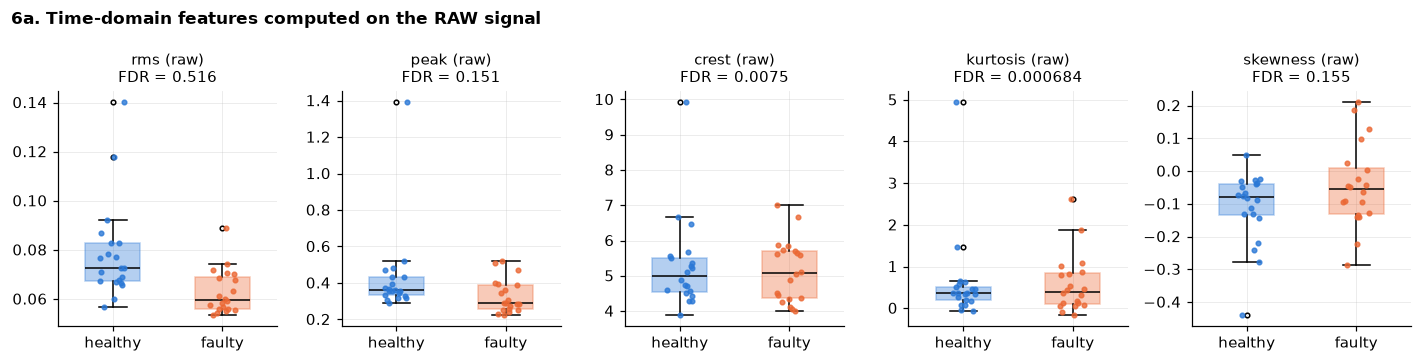

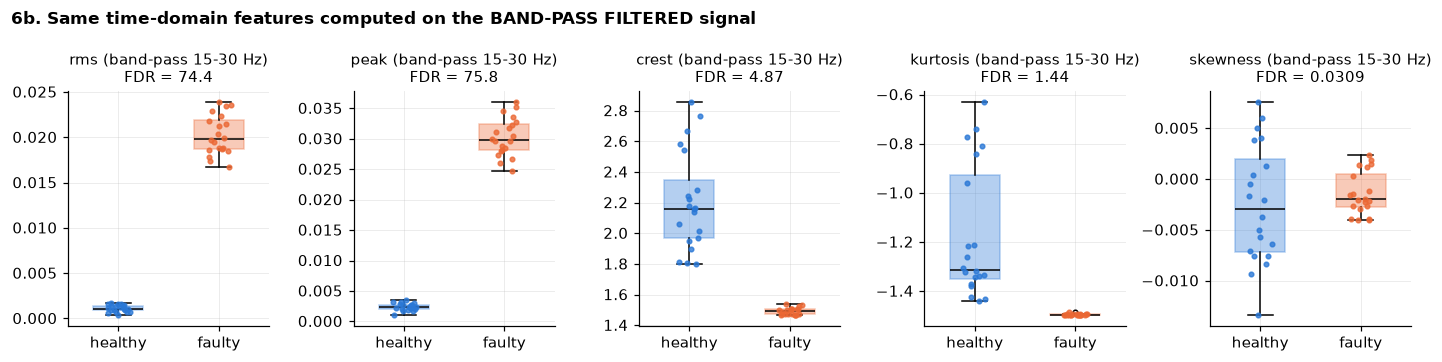

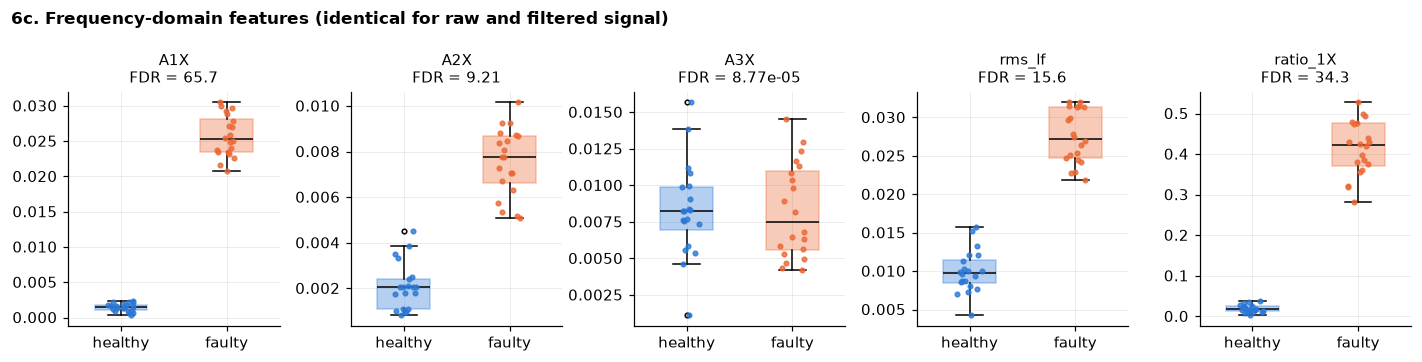

In [11]:
# Helper: one box plot panel (healthy vs faulty) with jittered raw points.
rng = np.random.default_rng(0)
def fdr_of(feat):
    h, fl = train.loc[train.label == 0, feat], train.loc[train.label == 1, feat]
    return (h.mean() - fl.mean()) ** 2 / (h.var() + fl.var())

def box_panel(ax, feat, title):
    title = f"{title}\nFDR = {fdr_of(feat):.3g}"
    data = [train.loc[train.label == 0, feat], train.loc[train.label == 1, feat]]
    bp = ax.boxplot(data, widths=0.5, patch_artist=True, medianprops=dict(color="black", lw=1),
                    flierprops=dict(marker="o", markersize=3, markerfacecolor="none"))
    for patch, c in zip(bp["boxes"], (C_HEALTHY, C_FAULTY)):
        patch.set(facecolor=c, alpha=0.35, edgecolor=c)
    for i, (d, c) in enumerate(zip(data, (C_HEALTHY, C_FAULTY)), start=1):
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(d)), d, s=9, color=c, alpha=0.8, zorder=3)
    ax.set_xticks([1, 2]); ax.set_xticklabels(["healthy", "faulty"]); ax.set_title(title, fontsize=9.5)

# Figure 6a: time-domain features of the RAW signal.
fig, axes = plt.subplots(1, 5, figsize=(13, 3.3))
for ax, st in zip(axes, TD_STATS):
    box_panel(ax, f"{st}_raw", f"{st} (raw)")
fig.suptitle("6a. Time-domain features computed on the RAW signal", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout(); plt.show()

# Figure 6b: the same five features computed on the BAND-PASS FILTERED (15-30 Hz) signal.
fig, axes = plt.subplots(1, 5, figsize=(13, 3.3))
for ax, st in zip(axes, TD_STATS):
    box_panel(ax, f"{st}_bp", f"{st} (band-pass 15-30 Hz)")
fig.suptitle("6b. Same time-domain features computed on the BAND-PASS FILTERED signal", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout(); plt.show()

# Figure 6c: frequency-domain features (unaffected by filtering).
fig, axes = plt.subplots(1, 5, figsize=(13, 3.3))
for ax, feat in zip(axes, FEATURES_SPEC):
    box_panel(ax, feat, feat)
fig.suptitle("6c. Frequency-domain features (identical for raw and filtered signal)", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout(); plt.show()

In [12]:
# Fisher discriminant ratio and Welch t-test for every feature.
def separability(feat):
    h, fl = train.loc[train.label == 0, feat], train.loc[train.label == 1, feat]
    tstat, pval = stats.ttest_ind(h, fl, equal_var=False)
    return (h.mean() - fl.mean()) ** 2 / (h.var() + fl.var()), abs(tstat), pval

rows = []
for feat in FEATURES:
    fdr, tt, pv = separability(feat)
    group = "frequency-domain" if feat in FEATURES_SPEC else ("time-domain, raw" if feat.endswith("_raw") else "time-domain, band-pass")
    rows.append({"feature": feat, "group": group, "FDR": fdr, "|t|": tt, "p-value": pv})
ranking = pd.DataFrame(rows).sort_values("FDR", ascending=False).reset_index(drop=True)

# Side-by-side table for the time-domain features: raw vs band-pass, and the gain factor from filtering.
compare = pd.DataFrame({
    "FDR raw": [separability(f"{st}_raw")[0] for st in TD_STATS],
    "FDR band-pass": [separability(f"{st}_bp")[0] for st in TD_STATS],
    "p-value raw": [separability(f"{st}_raw")[2] for st in TD_STATS],
    "p-value band-pass": [separability(f"{st}_bp")[2] for st in TD_STATS],
}, index=pd.Index(TD_STATS, name="time-domain feature"))
compare["FDR gain (x)"] = compare["FDR band-pass"] / compare["FDR raw"]
print("Reference: FDR of the 1X amplitude =", f"{separability('A1X')[0]:.1f}")
compare.style.format({"FDR raw": "{:.3f}", "FDR band-pass": "{:.3f}", "p-value raw": "{:.2e}", "p-value band-pass": "{:.2e}", "FDR gain (x)": "{:,.0f}"})

Reference: FDR of the 1X amplitude = 65.7


,FDR raw,FDR band-pass,p-value raw,p-value band-pass,FDR gain (x)
time-domain feature,,,,,
rms,0.516,74.351,3.42e-03,2.02e-20,144
peak,0.151,75.803,9.48e-02,1.37e-20,502
crest,0.008,4.868,7.01e-01,5.94e-09,649
kurtosis,0.001,1.442,9.08e-01,3.50e-05,"2,108"
skewness,0.155,0.031,8.69e-02,4.39e-01,0


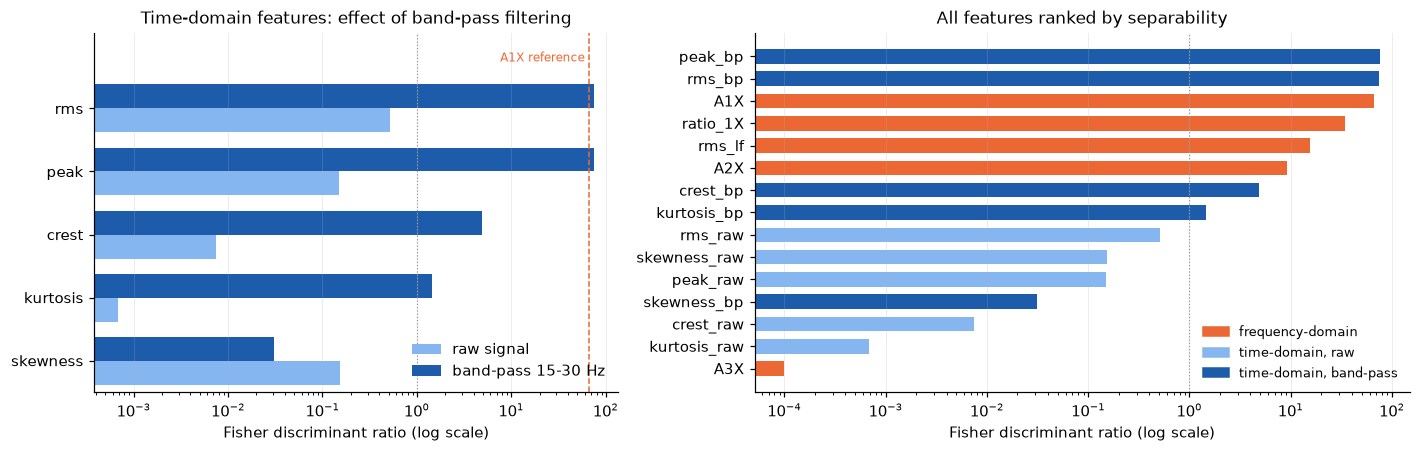

feature,group,FDR,|t|,p-value
peak_bp,"time-domain, band-pass",75.803,38.94,1.37e-20
rms_bp,"time-domain, band-pass",74.351,38.56,2.02e-20
A1X,frequency-domain,65.711,36.25,4.45e-20
ratio_1X,frequency-domain,34.300,26.19,8.76e-17
rms_lf,frequency-domain,15.580,17.65,2.15e-19
A2X,frequency-domain,9.212,13.57,2.58e-15
crest_bp,"time-domain, band-pass",4.868,9.87,5.94e-09
kurtosis_bp,"time-domain, band-pass",1.442,5.37,3.50e-05
rms_raw,"time-domain, raw",0.516,3.21,3.42e-03
skewness_raw,"time-domain, raw",0.155,1.76,8.69e-02


In [13]:
# Paired bar chart: Fisher ratio of each time-domain feature before (raw) and after (band-pass) filtering.
C_RAW, C_BP = "#86b6ef", "#1c5cab"
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
ypos = np.arange(len(TD_STATS)); h = 0.38
ax.barh(ypos + h / 2, compare["FDR raw"].clip(lower=1e-4), height=h, color=C_RAW, label="raw signal")
ax.barh(ypos - h / 2, compare["FDR band-pass"].clip(lower=1e-4), height=h, color=C_BP, label="band-pass 15-30 Hz")
ax.axvline(separability("A1X")[0], color=C_FAULTY, ls="--", lw=1.0)
ax.text(separability("A1X")[0], -0.8, "A1X reference ", color=C_FAULTY, fontsize=8, ha="right", va="center")
ax.axvline(1, color="0.6", ls=":", lw=0.8)
ax.set_yticks(ypos); ax.set_yticklabels(TD_STATS); ax.set_ylim(len(TD_STATS) - 0.5, -1.2)   # inverted, with headroom for the label
ax.set(xscale="log", xlabel="Fisher discriminant ratio (log scale)", title="Time-domain features: effect of band-pass filtering")
ax.grid(axis="y", visible=False); ax.legend(loc="lower right")

# Overall ranking of all features, colored by group.
ax = axes[1]
group_color = {"frequency-domain": C_FAULTY, "time-domain, raw": C_RAW, "time-domain, band-pass": C_BP}
rk = ranking[::-1]
ax.barh(rk.feature, rk.FDR.clip(lower=1e-4), color=[group_color[g] for g in rk.group], height=0.65)
ax.axvline(1, color="0.6", ls=":", lw=0.8)
ax.set(xscale="log", xlabel="Fisher discriminant ratio (log scale)", title="All features ranked by separability")
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=g) for g, c in group_color.items()], loc="lower right", fontsize=8.5)
fig.tight_layout(); plt.show()
ranking.style.format({"FDR": "{:.3f}", "|t|": "{:.2f}", "p-value": "{:.2e}"}).hide(axis="index")

**How filtering changes the feature selection result.**

* **Frequency-domain features are unchanged** (A1X FDR = 66, ratio_1X 34, rms_lf 16, A2X 9, A3X 0), as expected from section 4.3.
* **Raw time-domain features are all useless**: the best one, RMS, has FDR = 0.5 and the class distributions overlap almost completely; crest factor and kurtosis are at 0.01 and 0.001. The 400-800 Hz structural content that dominates the raw waveform is the same in both classes, so any statistic of the raw waveform is blind to the unbalance.
* **Band-pass filtering turns four of the five into strong features**: RMS goes from 0.5 to 74 (x144), peak from 0.15 to 76 (x500), crest factor from 0.01 to 4.9 and kurtosis from 0.001 to 1.4. After filtering the top two features of the whole ranking are `peak_bp` and `rms_bp`, slightly ahead of the 1X amplitude itself.
* **Skewness is the exception**: it stays useless (0.16 raw, 0.03 filtered) because both a sinusoid and Gaussian-like noise are symmetric, so no filter can make it informative.
* **The filtered features are not new information.** For a pure sinusoid the peak equals its amplitude and the RMS equals amplitude / sqrt(2), so `peak_bp` and `rms_bp` are simply time-domain estimates of the same 1X amplitude that the FFT measures directly (their crest factor sits at sqrt(2) = 1.41 for the faulty records). Band-pass filtering does not add a different health indicator; it makes the time domain *see* the indicator that the spectrum isolates by construction. This is why the four models in section 7 end up agreeing on every test record.

For the models below, the 1X amplitude remains the primary feature (model A), the harmonics form model B, all 15 features form model C, and the two best filtered time-domain features (`rms_bp`, `crest_bp`) form model D as an FFT-free alternative.

## 7. Logistic regression
### 7.1 Implementation from scratch
Logistic regression models P(faulty | x) = σ(w·x + b) with σ(z) = 1/(1+e^{-z}). The weights are found by maximizing the log-likelihood with Newton-Raphson (iteratively reweighted least squares). A small L2 penalty (λ) keeps the solution finite when the classes are perfectly separable, which is the case here. Features are standardized before fitting so the penalty acts evenly on all coefficients.

In [14]:
# Minimal logistic regression classifier (Newton-Raphson / IRLS with L2 penalty on the weights, not the intercept).
class LogisticRegressionScratch:
    def __init__(self, l2=1.0, max_iter=100, tol=1e-10):
        self.l2, self.max_iter, self.tol = l2, max_iter, tol

    @staticmethod
    def _sigmoid(z):
        return 1.0 / (1.0 + np.exp(-z))

    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y, float)
        Xb = np.c_[np.ones(len(X)), X]                       # prepend the intercept column
        w = np.zeros(Xb.shape[1])
        R = self.l2 * np.eye(Xb.shape[1]); R[0, 0] = 0.0      # do not penalize the intercept
        self.history_ = []
        for it in range(self.max_iter):
            p = self._sigmoid(Xb @ w)
            grad = Xb.T @ (p - y) + R @ w                      # gradient of the negative penalized log-likelihood
            H = (Xb * (p * (1 - p))[:, None]).T @ Xb + R        # Hessian
            step = np.linalg.solve(H, grad)
            w -= step
            nll = -np.sum(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12)) + 0.5 * self.l2 * w[1:] @ w[1:]
            self.history_.append(nll)
            if np.linalg.norm(step) < self.tol:
                break
        self.intercept_, self.coef_, self.n_iter_ = w[0], w[1:], it + 1
        return self

    def predict_proba(self, X):
        return self._sigmoid(np.asarray(X, float) @ self.coef_ + self.intercept_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

# Validate on the standardized 1X feature against scikit-learn (same objective: sklearn's C = 1 / lambda).
scaler_1x = StandardScaler().fit(train[["A1X"]])
Z1 = scaler_1x.transform(train[["A1X"]]); y = train.label.values
scratch = LogisticRegressionScratch(l2=1.0).fit(Z1, y)
sk = LogisticRegression(C=1.0).fit(Z1, y)
print(f"scratch : intercept = {scratch.intercept_: .5f}, coef = {scratch.coef_[0]: .5f}, converged in {scratch.n_iter_} Newton steps")
print(f"sklearn : intercept = {sk.intercept_[0]: .5f}, coef = {sk.coef_[0][0]: .5f}")
print("max |P_scratch - P_sklearn| on training data:", np.abs(scratch.predict_proba(Z1) - sk.predict_proba(Z1)[:, 1]).max())

scratch : intercept =  0.07492, coef =  2.67037, converged in 7 Newton steps
sklearn : intercept =  0.07443, coef =  2.67033
max |P_scratch - P_sklearn| on training data: 7.113524849344799e-05


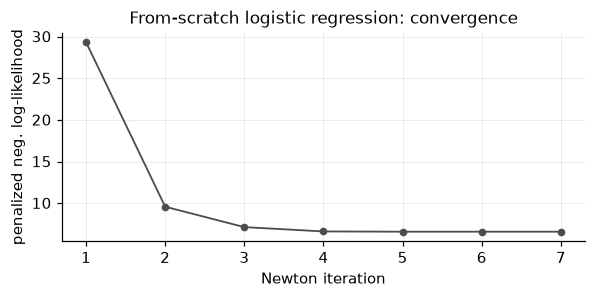

In [15]:
# Convergence of the Newton iterations (penalized negative log-likelihood per step).
fig, ax = plt.subplots(figsize=(5.5, 2.8))
ax.plot(range(1, len(scratch.history_) + 1), scratch.history_, marker="o", ms=4, color="0.3")
ax.set(xlabel="Newton iteration", ylabel="penalized neg. log-likelihood", title="From-scratch logistic regression: convergence")
fig.tight_layout(); plt.show()

### 7.2 Four logistic regression models
Each model is a scikit-learn pipeline (standardization + logistic regression, C = 1). Model performance is estimated with leave-one-out and stratified 5-fold cross-validation on the 40 training records.

In [16]:
# Define the four feature sets / models and evaluate them with cross-validation.
MODELS = {
    "A: 1X only":         ["A1X"],
    "B: harmonics 1X-3X": ["A1X", "A2X", "A3X"],
    "C: all features":    FEATURES,
    "D: band-pass time-domain": ["rms_bp", "crest_bp"],
}
def make_model():
    return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000))

fitted, cv_rows = {}, []
for name, feats in MODELS.items():
    X = train[feats].values
    fitted[name] = make_model().fit(X, y)
    loo = cross_val_score(make_model(), X, y, cv=LeaveOneOut()).mean()
    kf = cross_val_score(make_model(), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0)).mean()
    cv_rows.append({"model": name, "n_features": len(feats), "train accuracy": fitted[name].score(X, y),
                    "LOO-CV accuracy": loo, "5-fold CV accuracy": kf})
pd.DataFrame(cv_rows).set_index("model")

,n_features,train accuracy,LOO-CV accuracy,5-fold CV accuracy
model,,,,
A: 1X only,1,1.0,1.0,1.0
B: harmonics 1X-3X,3,1.0,1.0,1.0
C: all features,15,1.0,1.0,1.0
D: band-pass time-domain,2,1.0,1.0,1.0


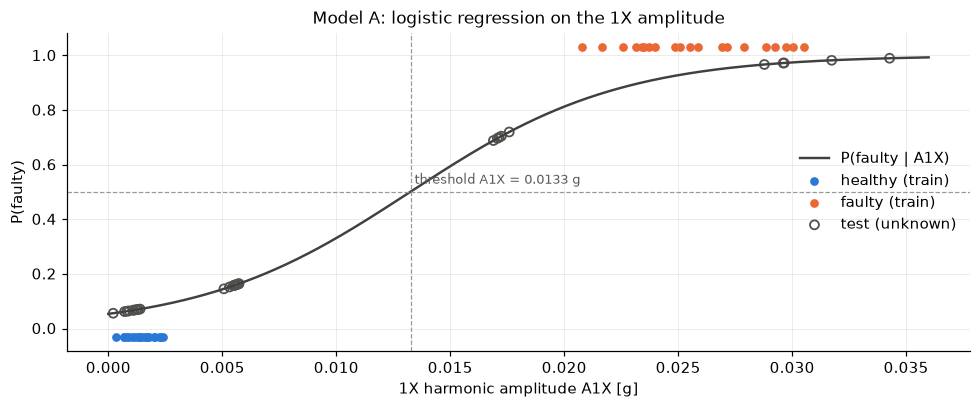

In [17]:
# Model A: fitted sigmoid over the 1X amplitude, with training points and the p = 0.5 decision threshold.
lr_a = fitted["A: 1X only"]
grid = np.linspace(0, max(train.A1X.max(), test.A1X.max()) * 1.05, 400)
p_grid = lr_a.predict_proba(grid[:, None])[:, 1]
thr_1x = grid[np.argmin(np.abs(p_grid - 0.5))]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(grid, p_grid, color="0.25", lw=1.6, label="P(faulty | A1X)")
ax.scatter(train.A1X[y == 0], np.zeros((y == 0).sum()) - 0.03, s=22, color=C_HEALTHY, label="healthy (train)")
ax.scatter(train.A1X[y == 1], np.ones((y == 1).sum()) + 0.03, s=22, color=C_FAULTY, label="faulty (train)")
ax.scatter(test.A1X, lr_a.predict_proba(test[["A1X"]].values)[:, 1], s=34, facecolor="none", edgecolor=C_TEST, lw=1.2, label="test (unknown)")
ax.axhline(0.5, color="0.6", ls="--", lw=0.8); ax.axvline(thr_1x, color="0.6", ls="--", lw=0.8)
ax.text(thr_1x, 0.53, f" threshold A1X = {thr_1x:.4f} g", fontsize=8.5, color="0.35")
ax.set(xlabel="1X harmonic amplitude A1X [g]", ylabel="P(faulty)", title="Model A: logistic regression on the 1X amplitude")
ax.legend(loc="center right"); fig.tight_layout(); plt.show()

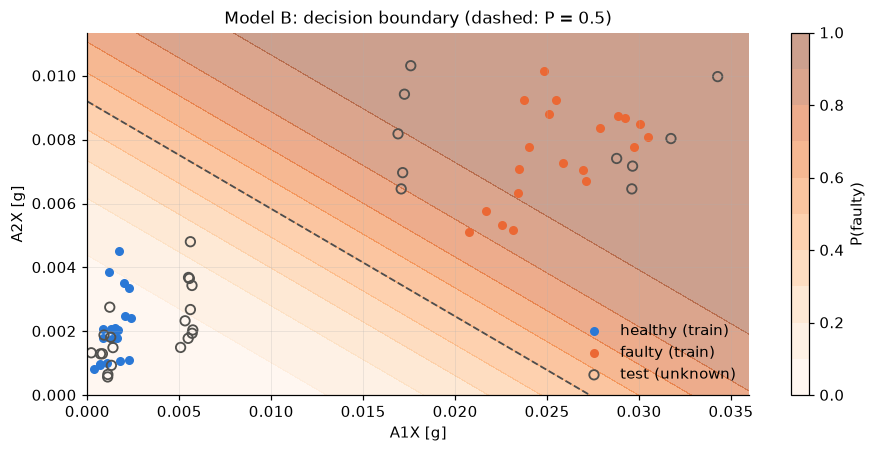

In [18]:
# Model B: decision boundary in the A1X-A2X plane (A3X fixed at its training mean) with the test records overlaid.
lr_b = fitted["B: harmonics 1X-3X"]
g1 = np.linspace(0, max(train.A1X.max(), test.A1X.max()) * 1.05, 250)
g2 = np.linspace(0, max(train.A2X.max(), test.A2X.max()) * 1.1, 250)
G1, G2 = np.meshgrid(g1, g2)
P = lr_b.predict_proba(np.c_[G1.ravel(), G2.ravel(), np.full(G1.size, train.A3X.mean())])[:, 1].reshape(G1.shape)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
cs = ax.contourf(G1, G2, P, levels=np.linspace(0, 1, 11), cmap="Oranges", alpha=0.45)
ax.contour(G1, G2, P, levels=[0.5], colors="0.3", linewidths=1.2, linestyles="--")
ax.scatter(train.A1X[y == 0], train.A2X[y == 0], s=24, color=C_HEALTHY, label="healthy (train)")
ax.scatter(train.A1X[y == 1], train.A2X[y == 1], s=24, color=C_FAULTY, label="faulty (train)")
ax.scatter(test.A1X, test.A2X, s=38, facecolor="none", edgecolor=C_TEST, lw=1.2, label="test (unknown)")
fig.colorbar(cs, ax=ax, label="P(faulty)")
ax.set(xlabel="A1X [g]", ylabel="A2X [g]", title="Model B: decision boundary (dashed: P = 0.5)")
ax.legend(loc="lower right"); fig.tight_layout(); plt.show()

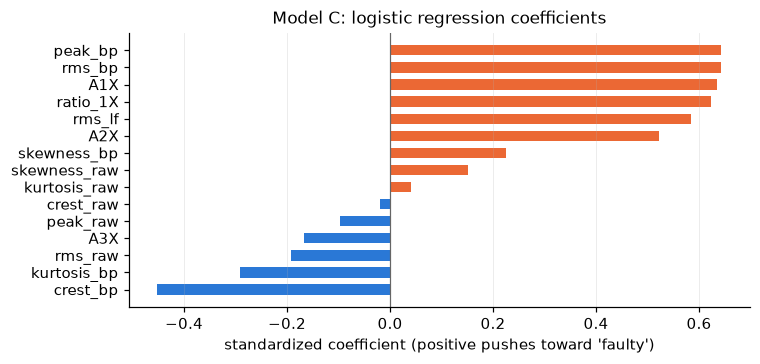

In [19]:
# Model C: standardized coefficients show which features drive the all-feature model.
lr_c = fitted["C: all features"]
coef = pd.Series(lr_c[-1].coef_[0], index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(coef.index, coef.values, color=[C_FAULTY if v >= 0 else C_HEALTHY for v in coef.values], height=0.6)
ax.axvline(0, color="0.4", lw=0.8); ax.grid(axis="y", visible=False)
ax.set(xlabel="standardized coefficient (positive pushes toward 'faulty')", title="Model C: logistic regression coefficients")
fig.tight_layout(); plt.show()

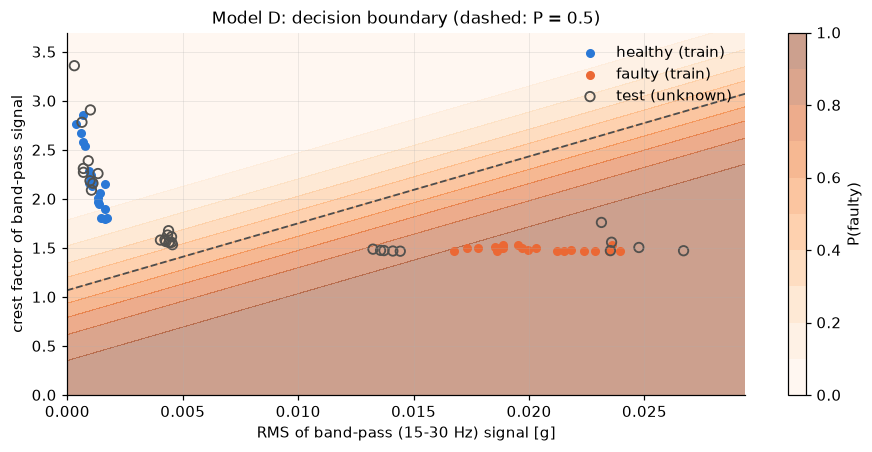

In [20]:
# Model D: decision boundary in the band-pass RMS / crest-factor plane (time-domain features only, no FFT).
lr_d = fitted["D: band-pass time-domain"]
g1 = np.linspace(0, max(train.rms_bp.max(), test.rms_bp.max()) * 1.1, 250)
g2 = np.linspace(0, max(train.crest_bp.max(), test.crest_bp.max()) * 1.1, 250)
G1, G2 = np.meshgrid(g1, g2)
P = lr_d.predict_proba(np.c_[G1.ravel(), G2.ravel()])[:, 1].reshape(G1.shape)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
cs = ax.contourf(G1, G2, P, levels=np.linspace(0, 1, 11), cmap="Oranges", alpha=0.45)
ax.contour(G1, G2, P, levels=[0.5], colors="0.3", linewidths=1.2, linestyles="--")
ax.scatter(train.rms_bp[y == 0], train.crest_bp[y == 0], s=24, color=C_HEALTHY, label="healthy (train)")
ax.scatter(train.rms_bp[y == 1], train.crest_bp[y == 1], s=24, color=C_FAULTY, label="faulty (train)")
ax.scatter(test.rms_bp, test.crest_bp, s=38, facecolor="none", edgecolor=C_TEST, lw=1.2, label="test (unknown)")
fig.colorbar(cs, ax=ax, label="P(faulty)")
ax.set(xlabel="RMS of band-pass (15-30 Hz) signal [g]", ylabel="crest factor of band-pass signal", title="Model D: decision boundary (dashed: P = 0.5)")
ax.legend(loc="upper right"); fig.tight_layout(); plt.show()

## 8. Health assessment of the test data
All 30 test records are scored with the four models. Each record receives a probability of fault, a hard label (threshold 0.5), and a **health index** HI = 1 − P(faulty) from the primary model A (1 = healthy, 0 = faulty). The final label is the majority vote of the four models (ties broken by the mean probability); records where the models disagree are flagged.

In [21]:
# Score every test record with the four models and assemble the results table.
res = test[["file", "time", "A1X", "A2X", "rms_raw", "rms_bp"]].copy()
for name, feats in MODELS.items():
    key = name.split(":")[0]
    res[f"P_fault_{key}"] = fitted[name].predict_proba(test[feats].values)[:, 1]
    res[f"label_{key}"] = np.where(res[f"P_fault_{key}"] >= 0.5, "faulty", "healthy")
label_cols = [f"label_{k}" for k in "ABCD"]
votes = (res[label_cols] == "faulty").sum(axis=1)
mean_p = res[[f"P_fault_{k}" for k in "ABCD"]].mean(axis=1)
res["final_label"] = np.where((votes > 2) | ((votes == 2) & (mean_p >= 0.5)), "FAULTY", "HEALTHY")
res["models_agree"] = (votes == 0) | (votes == len(label_cols))
res["health_index"] = 1 - res["P_fault_A"]
res.insert(0, "#", np.arange(1, len(res) + 1))
res.to_csv(OUT_DIR / "test_health_assessment.csv", index=False)

fmt = {c: "{:.4f}" for c in ["A1X", "A2X", "rms_raw", "rms_bp"]} | {c: "{:.3f}" for c in res.columns if c.startswith("P_fault") or c == "health_index"}
def color_label(v):
    return f"color: {C_FAULTY}; font-weight: bold" if v == "FAULTY" else (f"color: {C_HEALTHY}; font-weight: bold" if v == "HEALTHY" else "")
res.style.format(fmt).map(color_label, subset=["final_label"]).hide(axis="index")

#,file,time,A1X,A2X,rms_raw,rms_bp,P_fault_A,label_A,P_fault_B,label_B,P_fault_C,label_C,P_fault_D,label_D,final_label,models_agree,health_index
1,Data Mar-26-14 Time 1533-21.txt,1533,0.0002,0.0013,0.0994,0.0003,0.056,healthy,0.025,healthy,0.001,healthy,0.001,healthy,HEALTHY,True,0.944
2,Data Mar-26-14 Time 1534-22.txt,1534,0.0007,0.0013,0.0784,0.0006,0.062,healthy,0.034,healthy,0.006,healthy,0.006,healthy,HEALTHY,True,0.938
3,Data Mar-26-14 Time 1540-23.txt,1540,0.0012,0.0028,0.0711,0.0010,0.069,healthy,0.063,healthy,0.015,healthy,0.039,healthy,HEALTHY,True,0.931
4,Data Mar-26-14 Time 1540-24.txt,1540,0.0014,0.0015,0.0797,0.0011,0.071,healthy,0.050,healthy,0.013,healthy,0.043,healthy,HEALTHY,True,0.929
5,Data Mar-26-14 Time 1540-25.txt,1540,0.0013,0.0018,0.0941,0.0010,0.069,healthy,0.052,healthy,0.014,healthy,0.052,healthy,HEALTHY,True,0.931
6,Data Mar-26-14 Time 1543-26.txt,1543,0.0011,0.0006,0.0539,0.0009,0.067,healthy,0.015,healthy,0.014,healthy,0.021,healthy,HEALTHY,True,0.933
7,Data Mar-26-14 Time 1543-27.txt,1543,0.0009,0.0019,0.0590,0.0007,0.064,healthy,0.028,healthy,0.009,healthy,0.025,healthy,HEALTHY,True,0.936
8,Data Mar-26-14 Time 1543-28.txt,1543,0.0008,0.0013,0.0602,0.0007,0.063,healthy,0.038,healthy,0.011,healthy,0.028,healthy,HEALTHY,True,0.937
9,Data Mar-26-14 Time 1544-29.txt,1544,0.0011,0.0006,0.0633,0.0010,0.067,healthy,0.022,healthy,0.004,healthy,0.004,healthy,HEALTHY,True,0.933
10,Data Mar-26-14 Time 1544-30.txt,1544,0.0013,0.0009,0.0782,0.0013,0.070,healthy,0.028,healthy,0.011,healthy,0.033,healthy,HEALTHY,True,0.930


In [22]:
# Summary counts of the assessment.
print("Final labels:", res.final_label.value_counts().to_dict())
print("Records where the four models disagree:", int((~res.models_agree).sum()))
print("\nLabel counts by model:")
print(pd.DataFrame({k: res[f"label_{k}"].value_counts() for k in "ABCD"}).fillna(0).astype(int))

Final labels: {'HEALTHY': 20, 'FAULTY': 10}
Records where the four models disagree: 0

Label counts by model:
          A   B   C   D
healthy  20  20  20  20
faulty   10  10  10  10


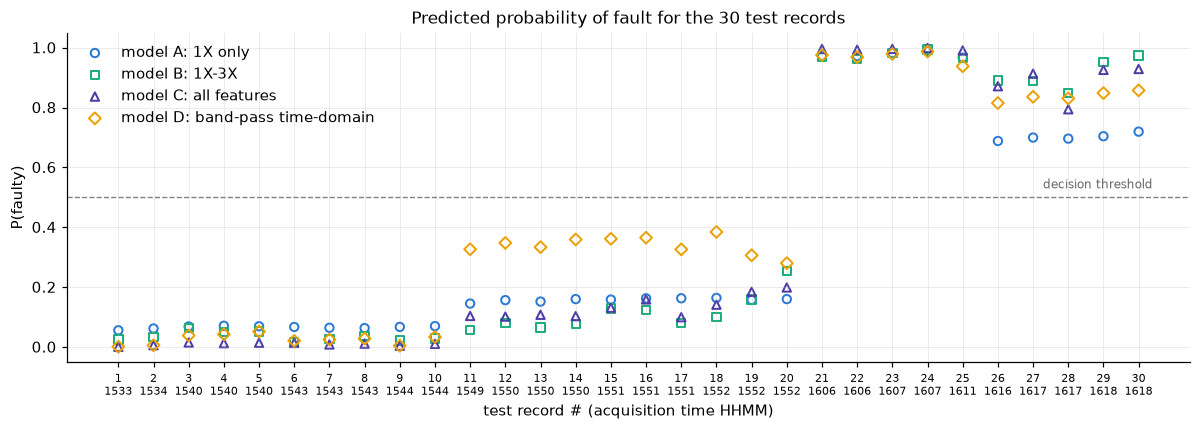

In [23]:
# Probability of fault for every test record (chronological order), one marker per model.
markers = {"A": ("o", "#2a78d6", "model A: 1X only"), "B": ("s", "#1baf7a", "model B: 1X-3X"), "C": ("^", "#4a3aa7", "model C: all features"), "D": ("D", "#eda100", "model D: band-pass time-domain")}
fig, ax = plt.subplots(figsize=(11, 4))
for k, (mk, c, lab) in markers.items():
    ax.scatter(res["#"], res[f"P_fault_{k}"], marker=mk, s=30, facecolor="none", edgecolor=c, lw=1.3, label=lab)
ax.axhline(0.5, color="0.5", ls="--", lw=0.9); ax.text(30.4, 0.53, "decision threshold", fontsize=8, color="0.4", ha="right")
ax.set_xticks(res["#"]); ax.set_xticklabels([f"{n}\n{t}" for n, t in zip(res["#"], res.time)], fontsize=7)
ax.set(xlabel="test record # (acquisition time HHMM)", ylabel="P(faulty)", ylim=(-0.05, 1.05), title="Predicted probability of fault for the 30 test records")
ax.legend(loc="upper left"); fig.tight_layout(); plt.show()

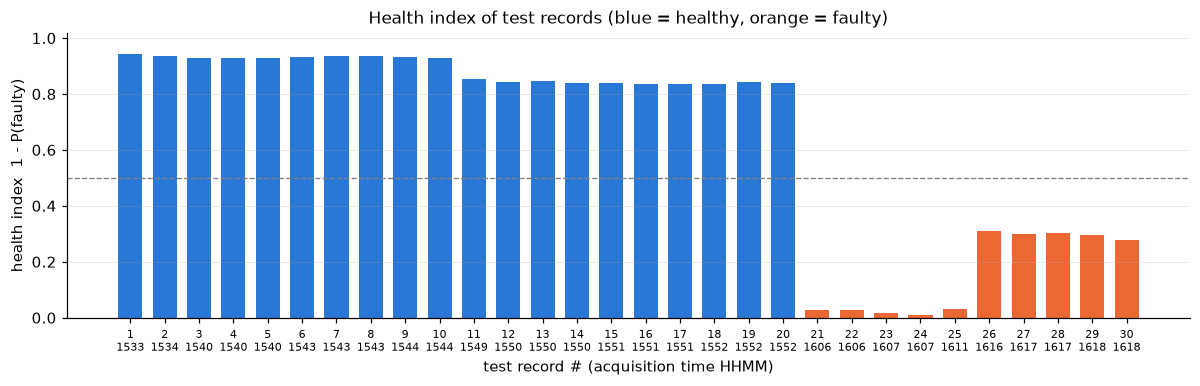

In [24]:
# Health index (model A) per test record, colored by the final majority-vote label.
fig, ax = plt.subplots(figsize=(11, 3.6))
colors = [C_FAULTY if l == "FAULTY" else C_HEALTHY for l in res.final_label]
ax.bar(res["#"], res.health_index, color=colors, width=0.7)
ax.axhline(0.5, color="0.5", ls="--", lw=0.9)
ax.set_xticks(res["#"]); ax.set_xticklabels([f"{n}\n{t}" for n, t in zip(res["#"], res.time)], fontsize=7)
ax.set(xlabel="test record # (acquisition time HHMM)", ylabel="health index  1 - P(faulty)", ylim=(0, 1.02), title="Health index of test records (blue = healthy, orange = faulty)")
ax.grid(axis="x", visible=False); fig.tight_layout(); plt.show()

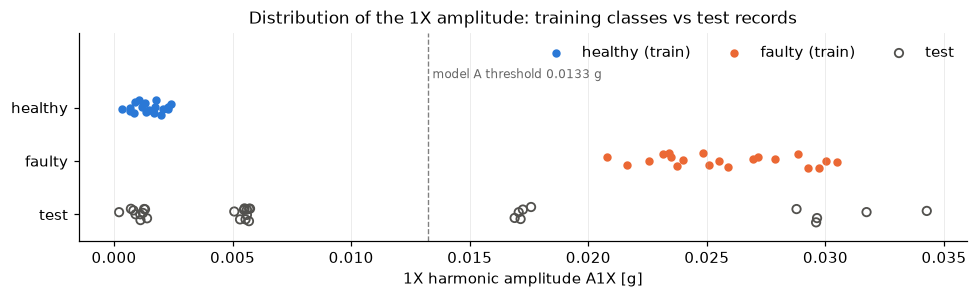

In [25]:
# Test records on the A1X axis alongside the training classes: reveals the intermediate group.
fig, ax = plt.subplots(figsize=(9, 2.8))
rng = np.random.default_rng(1)
ax.scatter(train.A1X[y == 0], rng.uniform(-0.15, 0.15, (y == 0).sum()) + 2, s=20, color=C_HEALTHY, label="healthy (train)")
ax.scatter(train.A1X[y == 1], rng.uniform(-0.15, 0.15, (y == 1).sum()) + 1, s=20, color=C_FAULTY, label="faulty (train)")
ax.scatter(res.A1X, rng.uniform(-0.15, 0.15, len(res)) + 0, s=30, facecolor="none", edgecolor=C_TEST, lw=1.2, label="test")
ax.axvline(thr_1x, color="0.5", ls="--", lw=0.9); ax.text(thr_1x, 2.55, f" model A threshold {thr_1x:.4f} g", fontsize=8, color="0.4")
ax.set_yticks([0, 1, 2]); ax.set_yticklabels(["test", "faulty", "healthy"]); ax.set_ylim(-0.5, 3.4)
ax.set(xlabel="1X harmonic amplitude A1X [g]", title="Distribution of the 1X amplitude: training classes vs test records")
ax.grid(axis="y", visible=False); ax.legend(loc="upper right", ncol=3); fig.tight_layout(); plt.show()

In [26]:
# Group the test records by acquisition-time cluster to summarise the assessment compactly.
def time_group(t):
    h, m = int(t[:2]), int(t[2:])
    return "15:33-15:44" if h == 15 and m < 48 else ("15:49-15:52" if h == 15 else ("16:06-16:11" if m <= 11 else "16:16-16:18"))
res["time_group"] = res.time.map(time_group)
summary = res.groupby("time_group").agg(records=("file", "count"), mean_A1X=("A1X", "mean"), mean_P_fault_A=("P_fault_A", "mean"),
                                        mean_P_fault_B=("P_fault_B", "mean"), mean_P_fault_C=("P_fault_C", "mean"), mean_P_fault_D=("P_fault_D", "mean"),
                                        n_faulty_final=("final_label", lambda s: (s == "FAULTY").sum()))
summary

,records,mean_A1X,mean_P_fault_A,mean_P_fault_B,mean_P_fault_C,mean_P_fault_D,n_faulty_final
time_group,,,,,,,
15:33-15:44,10,0.00101,0.06589,0.03536,0.00987,0.02517,0
15:49-15:52,10,0.00553,0.15800,0.11244,0.13323,0.33921,0
16:06-16:11,5,0.03081,0.97660,0.97475,0.99500,0.96965,5
16:16-16:18,5,0.01719,0.70166,0.91115,0.88681,0.83759,5


### 8.1 Decision boundary and logistic curve
Two summary graphs built on a two-feature logistic regression (the two spectral features `A1X` and `A2X`; change `PAIR` to try another pair). Filled circles are the training records (blue = healthy, orange = faulty). Diamonds are the 30 test records, hollow and edge-colored by the class the model assigns them; each test cluster is labelled with its record numbers.

In [27]:
# Fit a two-feature logistic regression and precompute everything both graphs need.
PAIR = ["A1X", "A2X"]
lr_pair = make_model().fit(train[PAIR].values, y)

test_p = lr_pair.predict_proba(test[PAIR].values)[:, 1]
test_pred = np.where(test_p >= 0.5, "faulty", "healthy")
test_edge = np.where(test_pred == "faulty", C_FAULTY, C_HEALTHY)

# Label each test cluster with its record-number range (clusters follow the acquisition time groups).
cluster_labels = res.groupby("time_group")["#"].agg(lambda n: f"#{n.min()}-{n.max()}")
res["cluster"] = res.time_group.map(cluster_labels)
print("test records assigned by the 2-feature model:", pd.Series(test_pred).value_counts().to_dict())

test records assigned by the 2-feature model: {'healthy': 20, 'faulty': 10}


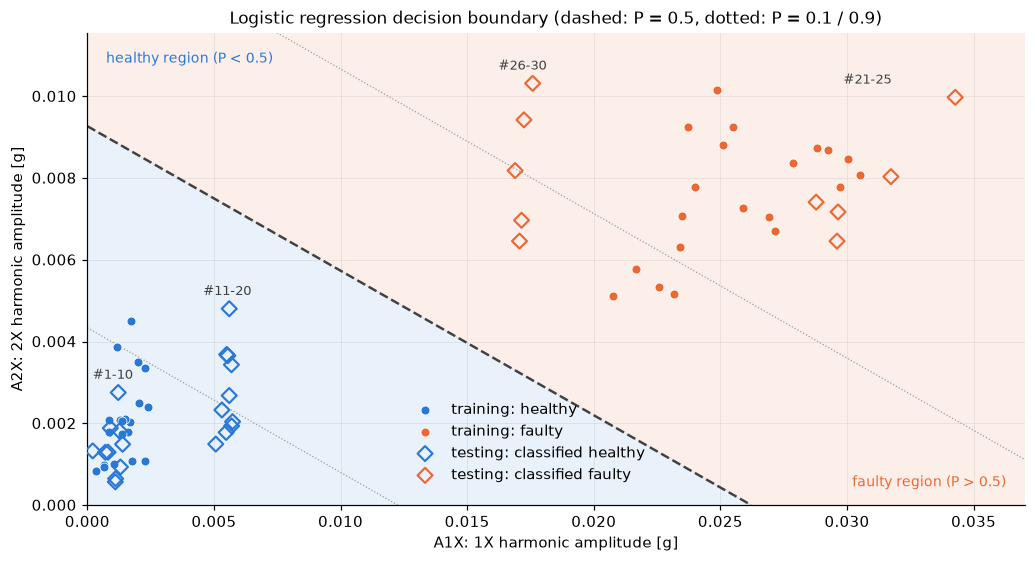

In [28]:
# Graph 1: decision boundary in the A1X-A2X plane with training and test records.
g1 = np.linspace(0, max(train[PAIR[0]].max(), test[PAIR[0]].max()) * 1.08, 300)
g2 = np.linspace(0, max(train[PAIR[1]].max(), test[PAIR[1]].max()) * 1.12, 300)
G1, G2 = np.meshgrid(g1, g2)
P = lr_pair.predict_proba(np.c_[G1.ravel(), G2.ravel()])[:, 1].reshape(G1.shape)

fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.contourf(G1, G2, P, levels=[0, 0.5, 1], colors=[C_HEALTHY, C_FAULTY], alpha=0.10)          # two regions
ax.contour(G1, G2, P, levels=[0.5], colors="0.25", linewidths=1.6, linestyles="--")               # boundary P = 0.5
ax.contour(G1, G2, P, levels=[0.1, 0.9], colors="0.6", linewidths=0.8, linestyles=":")            # P = 0.1 and 0.9
ax.scatter(train[PAIR[0]][y == 0], train[PAIR[1]][y == 0], s=34, color=C_HEALTHY, edgecolor="white", lw=0.5, label="training: healthy", zorder=3)
ax.scatter(train[PAIR[0]][y == 1], train[PAIR[1]][y == 1], s=34, color=C_FAULTY, edgecolor="white", lw=0.5, label="training: faulty", zorder=3)
for lab, c in [("healthy", C_HEALTHY), ("faulty", C_FAULTY)]:
    m = test_pred == lab
    ax.scatter(test[PAIR[0]][m], test[PAIR[1]][m], s=48, marker="D", facecolor="none", edgecolor=c, lw=1.4, label=f"testing: classified {lab}", zorder=4)
for cl, grp in res.groupby("cluster"):                                                             # cluster labels
    cx, cy = test.loc[grp.index, PAIR[0]].mean(), test.loc[grp.index, PAIR[1]].max()
    ax.annotate(cl, (cx, cy), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8.5, color="0.25")
ax.text(0.98, 0.04, "faulty region (P > 0.5)", transform=ax.transAxes, ha="right", color=C_FAULTY, fontsize=9)
ax.text(0.02, 0.96, "healthy region (P < 0.5)", transform=ax.transAxes, ha="left", va="top", color=C_HEALTHY, fontsize=9)
ax.set(xlabel=f"{PAIR[0]}: 1X harmonic amplitude [g]", ylabel=f"{PAIR[1]}: 2X harmonic amplitude [g]",
       xlim=(g1[0], g1[-1]), ylim=(g2[0], g2[-1]), title="Logistic regression decision boundary (dashed: P = 0.5, dotted: P = 0.1 / 0.9)")
ax.legend(loc="lower center", bbox_to_anchor=(0.47, 0.02)); fig.tight_layout(); plt.show()

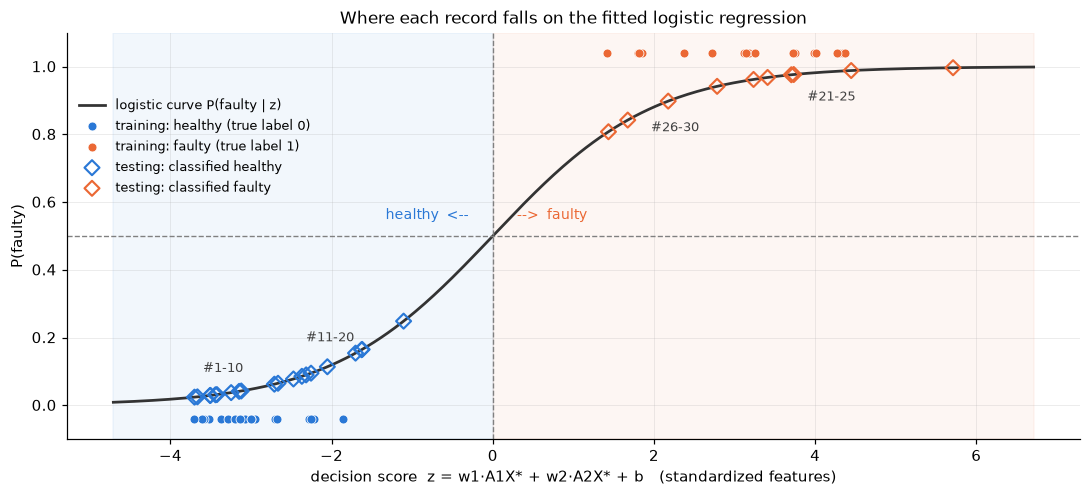

fitted model:  z = 1.939·A1X* + 1.339·A2X* + 0.157   (features standardized with training mean/std)


In [29]:
# Graph 2: the fitted logistic curve. Every record is placed at its decision score z = w·x + b; P(faulty) = 1 / (1 + e^-z).
z_train = lr_pair.decision_function(train[PAIR].values)
z_test = lr_pair.decision_function(test[PAIR].values)
zz = np.linspace(min(z_train.min(), z_test.min()) - 1, max(z_train.max(), z_test.max()) + 1, 400)

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.axvspan(zz[0], 0, color=C_HEALTHY, alpha=0.06); ax.axvspan(0, zz[-1], color=C_FAULTY, alpha=0.06)
ax.plot(zz, 1 / (1 + np.exp(-zz)), color="0.2", lw=1.8, label="logistic curve P(faulty | z)")
ax.axhline(0.5, color="0.5", ls="--", lw=0.9); ax.axvline(0, color="0.5", ls="--", lw=0.9)
# training records at their true class (0 = healthy, 1 = faulty), slightly offset from the curve for readability
ax.scatter(z_train[y == 0], np.full((y == 0).sum(), -0.04), s=34, color=C_HEALTHY, edgecolor="white", lw=0.5, label="training: healthy (true label 0)", zorder=3)
ax.scatter(z_train[y == 1], np.full((y == 1).sum(), 1.04), s=34, color=C_FAULTY, edgecolor="white", lw=0.5, label="training: faulty (true label 1)", zorder=3)
# test records sit on the curve at their predicted probability
for lab, c in [("healthy", C_HEALTHY), ("faulty", C_FAULTY)]:
    m = test_pred == lab
    ax.scatter(z_test[m], test_p[m], s=48, marker="D", facecolor="none", edgecolor=c, lw=1.4, label=f"testing: classified {lab}", zorder=4)
for cl, grp in res.groupby("cluster"):
    zc, pc = z_test[grp.index].mean(), test_p[grp.index].mean()
    ax.annotate(cl, (zc, pc), xytext=(0, -18 if pc > 0.5 else 14), textcoords="offset points", ha="center", fontsize=8.5, color="0.25")
ax.text(-0.3, 0.55, "healthy  <--", ha="right", color=C_HEALTHY, fontsize=9); ax.text(0.3, 0.55, "-->  faulty", ha="left", color=C_FAULTY, fontsize=9)
ax.set(xlabel="decision score  z = w1·A1X* + w2·A2X* + b   (standardized features)", ylabel="P(faulty)", ylim=(-0.1, 1.1),
       title="Where each record falls on the fitted logistic regression")
ax.legend(loc="center left", bbox_to_anchor=(0.0, 0.72), fontsize=8.5); fig.tight_layout(); plt.show()
w, b = lr_pair[-1].coef_[0], lr_pair[-1].intercept_[0]
print(f"fitted model:  z = {w[0]:.3f}·A1X* + {w[1]:.3f}·A2X* + {b:.3f}   (features standardized with training mean/std)")

## 9. Discussion
**Shaft speed.** The dominant low-frequency line sits at 21.0-21.07 Hz in every record, not at the nominal 20 Hz. Reading the spectrum at exactly 20 Hz would return noise-floor values and destroy the feature, so the 1X amplitude is taken as the peak inside a ±15 % band around the nominal speed and the 2X/3X amplitudes are located relative to the *measured* 1X frequency. Tracking the actual speed is essential for any order-based feature.

**Features.** The 1X amplitude is by far the most discriminative feature (Fisher ratio ≈ 66, healthy mean 0.0015 g vs faulty mean 0.0257 g, no overlap between the two training classes). Its normalized version (A1X / RMS) and the 0-100 Hz band RMS inherit that separability, and the 2X harmonic also grows with unbalance (0.002 g -> 0.0076 g). Broadband time-domain statistics (RMS, peak, crest factor, kurtosis, skewness) barely separate the classes because the overall vibration is dominated by structural / bearing content between 400 and 800 Hz that does not depend on unbalance; the healthy records even have a slightly *higher* RMS than the faulty ones. The 3X harmonic coincides with a fixed 63 Hz line present in both classes and carries no information. This is physically consistent: mass unbalance produces a synchronous (1X) rotating force, so a narrow-band synchronous feature beats any broadband statistic.

**Noise filtering.** Pre-filtering the waveform (zero-phase Butterworth low-pass at 100 Hz or band-pass 15-30 Hz) does not improve the frequency-domain feature at all: the 1X amplitude and its local signal-to-noise ratio (about 48 dB) are identical before and after filtering, because a linear filter with unit gain at 21 Hz leaves that bin unchanged and the 15-s FFT already confines the broadband noise to other bins. Filtering is decisive for the time domain, though. RMS, crest factor and kurtosis of the raw signal carry almost no class information (Fisher ratios below 0.6), while the RMS and the peak of the band-pass filtered signal reach Fisher ratios of about 75, slightly above the 1X amplitude itself (66), and the band-pass crest factor rises from 0.0 to about 5. In other words, filtering does not make the spectrum better, it makes the time domain usable.

**Modelling.** Because the classes are perfectly separable, the maximum-likelihood logistic regression has no finite solution; the L2 penalty (C = 1 on standardized features) is what keeps the coefficients finite and the sigmoid smooth. The from-scratch Newton-Raphson implementation converges in a handful of iterations and reproduces the scikit-learn coefficients to four decimals. All four models reach 100 % training, leave-one-out and 5-fold accuracy, so the training data alone cannot rank them; model A (1X only) is preferred for interpretability (a single threshold of about 0.013 g on the 1X amplitude), model B adds robustness through the 2X harmonic, and model D shows that, once the signal is band-pass filtered around 1X, two plain time-domain statistics (RMS and crest factor) classify just as well without any FFT.

**Test results.** The 30 test records fall into four clusters that follow the acquisition time:

| Records | Time | Mean A1X [g] | P(faulty), model A | Assessment |
|---|---|---|---|---|
| 1-10 | 15:33-15:44 | 0.0010 | 0.07 | healthy, indistinguishable from the healthy training set (recorded right after it) |
| 11-20 | 15:49-15:52 | 0.0055 | 0.16 | healthy label, but 1X is about 4x the healthy level: consistent with the unbalance level 1 (one screw) condition mentioned in the assignment, which is not in the training set |
| 21-25 | 16:06-16:11 | 0.0308 | 0.98 | faulty, matches unbalance level 2 (recorded right after the faulty training set) |
| 26-30 | 16:16-16:18 | 0.0172 | 0.70 (0.91 with model B) | faulty with moderate confidence; 1X lies between the level-1 and level-2 clusters, i.e. an intermediate severity or a different screw position |

The four models agree on the hard label of every test record (20 healthy, 10 faulty). They differ only in confidence: for records 26-30 the elevated 2X amplitude makes models B and C more certain than model A, and for records 11-20 the band-pass RMS used by model D gives P(faulty) ≈ 0.34 versus 0.16 for model A, so model D is the most sensitive to the mild unbalance. The continuous health index (1 - P) is more informative than the binary label here: it orders the four clusters correctly by unbalance severity even though the classifier was only trained on the two extreme conditions.

**Limitations.** Only two conditions were available for training, so an intermediate unbalance is forced into one of two classes. With a labelled level-1 data set the same features would support a three-class (multinomial) logistic regression or a regression of unbalance severity on the 1X amplitude. The decision threshold also depends on the regularization strength because the classes do not overlap; in practice it should be set from an engineering tolerance (e.g. an ISO vibration-severity limit) rather than from the margin between two training clusters.

## 10. Conclusion
* The 1X harmonic amplitude, extracted with a Hann-windowed FFT and a speed-tracking peak search (actual shaft speed ≈ 21.05 Hz), separates healthy and unbalanced shafts perfectly on the training data; the 2X harmonic is a useful secondary feature, while broadband time-domain statistics are not.
* Noise filtering does not change the FFT-based 1X amplitude (the 15-s FFT already isolates the 21 Hz line), but band-pass filtering around 1X turns the otherwise useless time-domain statistics into strong features: the band-pass peak and RMS become the best single features (Fisher ratios 76 and 74 vs 66 for the 1X amplitude), because for a sinusoid they are direct estimates of the same 1X amplitude.
* Logistic regression, implemented from scratch and cross-checked with scikit-learn, achieves 100 % leave-one-out accuracy with one, two, three or fifteen features. A single 1X threshold of ≈ 0.013 g is enough for a binary decision.
* On the 30 unknown test records all four models agree: **records 1-20 are healthy and records 21-30 are faulty (unbalanced)**. Within these groups the health index further reveals a slightly unbalanced group (records 11-20, likely unbalance level 1) and a moderately unbalanced group (records 26-30) that would deserve attention before they progress.
* Results are saved to `results/test_health_assessment.csv` together with the extracted features for both the training and test sets.